In [28]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

project_root = Path("../../..").resolve()
sys.path.append(str(project_root))

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINConv, global_mean_pool

from utils import DataManager
from utils.plotter import actual_vs_prediction
torch.manual_seed(25)
np.random.seed(25)


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
dataset = DataManager('bioactivity/egfr', dataset_type='graph').dataset

train_dataset, test_dataset = train_test_split(dataset, test_size=0.2, random_state=25)

y_train_raw = np.array([d.y.item() for d in train_dataset], dtype=np.float32)
y_mean, y_std = y_train_raw.mean(), y_train_raw.std()
print(f"Target mean={y_mean:.4f}, std={y_std:.4f}")

def normalize(d):
    d.y = (d.y - y_mean) / y_std
    return d

train_dataset = [normalize(d.clone()) for d in train_dataset]
test_dataset = [normalize(d.clone()) for d in test_dataset]

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Target mean=6.6438, std=1.3276


In [4]:
class GINRegressor(nn.Module):
    def __init__(self, in_channels, hidden_feat=128, num_layers=3, dropout=0.2):
        super().__init__()

        self.convs = nn.ModuleList()
        self.bns = nn.ModuleList()

        for i in range(num_layers):
            input_dim = in_channels if i == 0 else hidden_feat

            mlp = nn.Sequential(
                nn.Linear(input_dim, hidden_feat),
                nn.BatchNorm1d(hidden_feat),
                nn.ReLU(),
                nn.Linear(hidden_feat, hidden_feat),
            )

            self.convs.append(GINConv(mlp, train_eps=True))
            self.bns.append(nn.BatchNorm1d(hidden_feat))

        self.dropout = dropout

        self.fc = nn.Sequential(
            nn.Linear(hidden_feat, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, data):
        x = data.x
        edge_index = data.edge_index
        batch = data.batch

        for i, (conv, bn) in enumerate(zip(self.convs, self.bns)):
            x_new = conv(x, edge_index)
            x_new = bn(x_new)

            if i < len(self.convs) - 1:
                x_new = F.relu(x_new)

            x_new = F.dropout(x_new, p=self.dropout, training=self.training)

            # residual connection once shapes match (all layers after the first)
            x = x_new + x if i > 0 else x_new

        x = global_mean_pool(x, batch)
        return self.fc(x)

In [5]:
in_channels = train_dataset[0].x.shape[1]
print(f"in_channels detected: {in_channels}")

model = GINRegressor(
    in_channels=in_channels,
    hidden_feat=128,      # reduced from 128 — less overfitting risk on small datasets
    num_layers=5,        # reduced from 5 — avoids oversmoothing
    dropout=0.2,
).to(device)

optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=15
)
criterion = nn.MSELoss()

in_channels detected: 6


In [6]:
def train(model, optimizer, criterion, loader):
    model.train()
    total_loss = 0
    for data in loader:
        data = data.to(device)
        optimizer.zero_grad()

        out = model(data).view(-1)
        y = data.y.view(-1)

        loss = criterion(out, y)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

        optimizer.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    y_true, y_pred = [], []

    for data in loader:
        data = data.to(device)
        out = model(data)
        y_true.extend(data.y.view(-1).cpu().numpy())
        y_pred.extend(out.view(-1).cpu().numpy())

    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    y_true_real = y_true * y_std + y_mean
    y_pred_real = y_pred * y_std + y_mean

    return {
        "y_true": y_true_real,
        "y_pred": y_pred_real,
        "mae": mean_absolute_error(y_true_real, y_pred_real),
        "mse": mean_squared_error(y_true_real, y_pred_real),
        "rmse": np.sqrt(mean_squared_error(y_true_real, y_pred_real)),
        "r2": r2_score(y_true, y_pred),  # r2 is scale-invariant, fine either way
    }

In [7]:
best_test_r2 = -np.inf
best_state = None
patience_counter = 0
early_stop_patience = 40

for epoch in range(500):
    train_loss = train(model, optimizer, criterion, train_loader)
    test_metrics = evaluate(model, test_loader)

    scheduler.step(train_loss)

    if test_metrics["r2"] > best_test_r2:
        best_test_r2 = test_metrics["r2"]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        patience_counter = 0
    else:
        patience_counter += 1

    if (epoch + 1) % 10 == 0:
        train_metrics = evaluate(model, train_loader)
        current_lr = optimizer.param_groups[0]['lr']
        print(
            f"Epoch {epoch+1:03d} | Loss {train_loss:.4f} | "
            f"Train R² {train_metrics['r2']:.4f} | Test R² {test_metrics['r2']:.4f} | "
            f"LR {current_lr:.2e}"
        )

    if patience_counter >= early_stop_patience:
        print(f"Early stopping at epoch {epoch+1} (best test R²={best_test_r2:.4f})")
        break

# Restore best model
model.load_state_dict(best_state)
final_metrics = evaluate(model, test_loader)
print(f"\nFinal (best) test metrics: {final_metrics}")

Epoch 010 | Loss 0.4587 | Train R² 0.6247 | Test R² 0.5850 | LR 1.00e-03
Epoch 020 | Loss 0.3925 | Train R² 0.6795 | Test R² 0.5988 | LR 1.00e-03
Epoch 030 | Loss 0.3570 | Train R² 0.7030 | Test R² 0.5856 | LR 1.00e-03
Epoch 040 | Loss 0.3470 | Train R² 0.7198 | Test R² 0.6111 | LR 1.00e-03
Epoch 050 | Loss 0.3044 | Train R² 0.7462 | Test R² 0.6291 | LR 1.00e-03
Epoch 060 | Loss 0.2899 | Train R² 0.7805 | Test R² 0.6399 | LR 1.00e-03
Epoch 070 | Loss 0.2917 | Train R² 0.7158 | Test R² 0.6173 | LR 1.00e-03
Epoch 080 | Loss 0.2627 | Train R² 0.7954 | Test R² 0.6419 | LR 1.00e-03
Epoch 090 | Loss 0.2689 | Train R² 0.8053 | Test R² 0.6371 | LR 1.00e-03
Epoch 100 | Loss 0.2568 | Train R² 0.7997 | Test R² 0.6208 | LR 1.00e-03
Epoch 110 | Loss 0.2196 | Train R² 0.8382 | Test R² 0.6425 | LR 1.00e-03
Epoch 120 | Loss 0.2314 | Train R² 0.8209 | Test R² 0.6713 | LR 1.00e-03
Epoch 130 | Loss 0.2088 | Train R² 0.8670 | Test R² 0.7058 | LR 5.00e-04
Epoch 140 | Loss 0.1923 | Train R² 0.8782 | Test R²

In [11]:
train_results = evaluate(model, train_loader)
test_results = evaluate(model, test_loader)


print("\n===== TRAINING RESULTS =====")

print(f"R²   : {train_results['r2']:.4f}")
print(f"MSE  : {train_results['mse']:.4f}")
print(f"RMSE : {train_results['rmse']:.4f}")
print(f"MAE  : {train_results['mae']:.4f}")


print("\n===== TESTING RESULTS =====")

print(f"R²   : {test_results['r2']:.4f}")
print(f"MSE  : {test_results['mse']:.4f}")
print(f"RMSE : {test_results['rmse']:.4f}")
print(f"MAE  : {test_results['mae']:.4f}")


===== TRAINING RESULTS =====
R²   : 0.9225
MSE  : 0.1366
RMSE : 0.3696
MAE  : 0.2753

===== TESTING RESULTS =====
R²   : 0.7332
MSE  : 0.4979
RMSE : 0.7057
MAE  : 0.5275


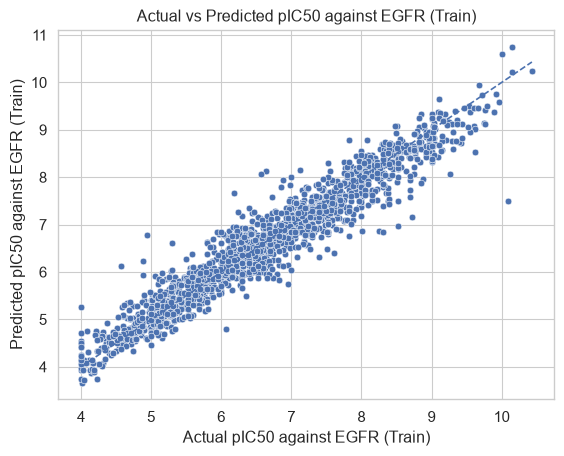

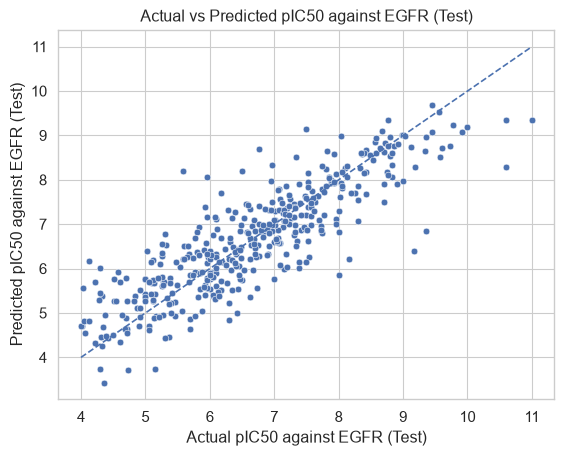

In [12]:
actual_vs_prediction(y_true=train_results['y_true'], y_pred=train_results['y_pred'], name="pIC50 against EGFR (Train)")
actual_vs_prediction(y_true=test_results['y_true'], y_pred=test_results['y_pred'], name="pIC50 against EGFR (Test)")

In [63]:
inf_df = DataManager(path='roselle_dataset', dataset_type='graph').dataset
inf_loader = DataLoader(inf_df, batch_size=32, shuffle=False)


In [66]:
@torch.no_grad()
def predict(model, loader, device="cuda"):
    model.eval()

    predictions = []

    for data in loader:
        data = data.to(device)

        output = model(data)

        output = output.view(-1)

        predictions.extend(output.cpu().numpy())

    return np.array(predictions)

In [67]:
predictions = predict(
    model,
    inf_loader,
    device="cuda"
)
predictions


array([-0.48391017, -0.3311645 , -0.42904285, ..., -1.6644942 ,
       -1.5714877 , -1.9831322 ], shape=(1284,), dtype=float32)

In [69]:
pred_raw = predictions * y_std + y_mean
pred_df = pd.DataFrame(pred_raw, columns=['pIC50 against EGFR'])

path_location = project_root / 'data' / 'final_dataset' / 'final_roselle_dataset.csv'
final_dataset = pd.read_csv(path_location)
final_dataset = pd.concat(objs=[final_dataset, pred_df], axis=1)
final_dataset.to_csv(path_location, index=False)